Environment Setup for Mario

In [1]:
!pip install --upgrade pip
!pip install gym_super_mario_bros==9.1.0 nes_py

In [2]:
import gym_super_mario_bros #name of the game
from nes_py.wrappers import JoypadSpace #importing Joypad wrapper
from gym_super_mario_bros.actions import SIMPLE_MOVEMENT 
import matplotlib.pyplot as plt
from IPython import display

In [3]:
SIMPLE_MOVEMENT  #actions that our AI will take to play the MARIO game

[['NOOP'],
 ['right'],
 ['right', 'A'],
 ['right', 'B'],
 ['right', 'A', 'B'],
 ['A'],
 ['left']]

In [4]:
#Set up the game env
env = gym_super_mario_bros.make('SuperMarioBros-v0')
env = JoypadSpace(env, SIMPLE_MOVEMENT) # Joypad Space simplifies the no of movements that AI has to learn to play the game

In [5]:
env.action_space

Discrete(7)

In [6]:
env.observation_space.shape #the screen play of the Mario game

(240, 256, 3)

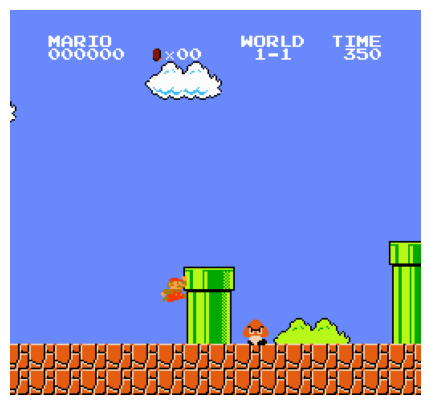

In [7]:
res = env.reset()
state = res[0] if isinstance(res, tuple) else res
done = False

# 3. Setup inline plot
fig, ax = plt.subplots(figsize=(7, 5))
img = ax.imshow(state)
plt.axis('off')

try:
    for step in range(1000):
        if done:
            res = env.reset()
            state = res[0] if isinstance(res, tuple) else res

        # Sample random action
        step_res = env.step(env.action_space.sample())
        
        # Unpack 5 values (newer gym) or 4 values (older gym)
        if len(step_res) == 5:
            state, reward, terminated, truncated, info = step_res
            done = terminated or truncated
        else:
            state, reward, done, info = step_res

        # Update inline display frame
        img.set_data(state)
        display.display(plt.gcf())
        display.clear_output(wait=True)

finally:
    env.close()
    plt.close(fig)

Preprocess the Maria Data

In [8]:
pip install stable-baselines3 shimmy

Note: you may need to restart the kernel to use updated packages.


In [9]:
%pip install torch torchvision torchaudio "stable-baselines3[extra]"

Note: you may need to restart the kernel to use updated packages.


In [10]:
from stable_baselines3.common.atari_wrappers import WarpFrame, MaxAndSkipEnv 
from stable_baselines3.common.vec_env import DummyVecEnv, VecFrameStack 
import matplotlib.pyplot as plt

print("Stable-Baselines3 imported successfully!")

Stable-Baselines3 imported successfully!


In [11]:
# 1. Helper function to create the wrapped base environment
def make_mario_env():
    # Base game
    env = gym_super_mario_bros.make('SuperMarioBros-v0')
    # Restrict actions to 7 movement combos
    env = JoypadSpace(env, SIMPLE_MOVEMENT)
    # Skip 4 frames and max-pool across last 2 frames
    env = MaxAndSkipEnv(env, skip=4)
    # Downsample to 84x84 grayscale
    env = WarpFrame(env, width=84, height=84)
    return env

# 2. Vectorize the environment
env = DummyVecEnv([make_mario_env])

# 3. Stack 4 frames together
env = VecFrameStack(env, n_stack=4, channels_order='last')

# Verify the observation shape
print("Observation Space:", env.observation_space.shape)

Observation Space: (84, 84, 4)


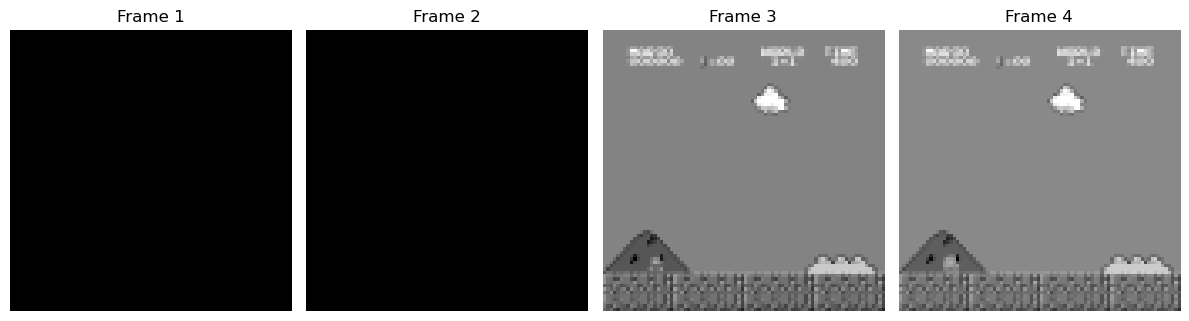

In [12]:
import matplotlib.pyplot as plt #to show the impact of frames stacking

# Reset the vectorized environment
state = env.reset()

# Take a random step
state, reward, done, info = env.step([env.action_space.sample()])

# Plot the 4 stacked grayscale channels side-by-side
plt.figure(figsize=(12, 4))
for i in range(state.shape[-1]):
    plt.subplot(1, 4, i + 1)
    plt.title(f"Frame {i + 1}")
    plt.imshow(state[0, :, :, i], cmap='gray')
    plt.axis('off')
plt.tight_layout()
plt.show()

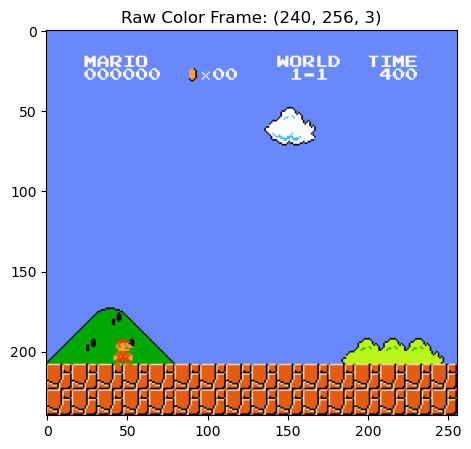

In [13]:
import gym_super_mario_bros
import matplotlib.pyplot as plt

# 1. Create a quick, raw un-wrapped environment
raw_env = gym_super_mario_bros.make('SuperMarioBros-v0')

# 2. Reset to fetch the raw starting frame (RGB: 240 x 256 x 3)
res = raw_env.reset()
raw_state = res[0] if isinstance(res, tuple) else res

# 3. Plot the full-color frame
plt.figure(figsize=(6, 5))
plt.imshow(raw_state)
plt.title(f"Raw Color Frame: {raw_state.shape}")
plt.axis('on')  # Shows pixel coordinates (256x240) just like the video
plt.show()

# 4. Close the temporary raw environment
raw_env.close()

In [14]:
import os
from stable_baselines3.common.callbacks import CheckpointCallback

CHECKPOINT_DIR = './train/'
LOG_DIR = './logs/'

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

# Save model weights every 10,000 steps
callback = CheckpointCallback(
    save_freq=10000, 
    save_path=CHECKPOINT_DIR, 
    name_prefix='mario_model'
)
print("Save callback initialized!")

Save callback initialized!


Train the model 

In [15]:
from stable_baselines3 import PPO

# 1. Initialize PPO agent
model = PPO(
    policy='CnnPolicy',
    env=env,
    verbose=1,
    learning_rate=1e-4,
    n_steps=512,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    tensorboard_log=LOG_DIR
)

# 2. Train the agent (starts with 10,000 steps for an initial test run)
model.learn(total_timesteps=10000, callback=callback)

# 3. Save the trained model
model.save("mario_model_test")
print("Model saved successfully!")

Using cpu device
Wrapping the env in a VecTransposeImage.
Logging to ./logs/PPO_1
----------------------------
| time/              |     |
|    fps             | 348 |
|    iterations      | 1   |
|    time_elapsed    | 1   |
|    total_timesteps | 512 |
----------------------------
-----------------------------------------
| time/                   |             |
|    fps                  | 197         |
|    iterations           | 2           |
|    time_elapsed         | 5           |
|    total_timesteps      | 1024        |
| train/                  |             |
|    approx_kl            | 0.009237536 |
|    clip_fraction        | 0.0813      |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.94       |
|    explained_variance   | 0.000899    |
|    learning_rate        | 0.0001      |
|    loss                 | 466         |
|    n_updates            | 10          |
|    policy_gradient_loss | -0.00638    |
|    value_loss           | 1.19e+03    |
-

Test the model

In [19]:
import os

print("Files in ./train/:", os.listdir('./train') if os.path.exists('./train') else "No ./train folder")
print("Files in current directory:", [f for f in os.listdir('.') if f.endswith('.zip')])

Files in ./train/: ['mario_model_10000_steps.zip']
Files in current directory: ['PetImages.zip', 'mario_model_test.zip']


In [20]:
model = PPO.load('./train/mario_model_10000_steps.zip')
print("Loaded successfully!")

Loaded successfully!


In [22]:
from stable_baselines3 import PPO

# Load the saved model
model = PPO.load("mario_model_test")
print("Trained model loaded successfully!")

Trained model loaded successfully!


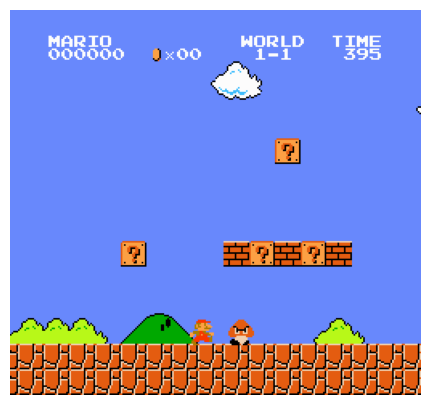

In [25]:
import matplotlib.pyplot as plt
from IPython import display

# 1. Reset preprocessed environment
state = env.reset()

# 2. Get the base un-wrapped nes-py emulator to extract raw color frames
raw_emulator = env.envs[0].unwrapped

# 3. Pull the native RGB frame directly from emulator memory
rgb_frame = raw_emulator.screen

# 4. Setup color plot
fig, ax = plt.subplots(figsize=(6, 5))
img = ax.imshow(rgb_frame)
plt.axis('off')

try:
    for step in range(2000):
        # AI predicts from the preprocessed 84x84 stacked state
        action, _ = model.predict(state, deterministic=True)
        state, reward, done, info = env.step(action)
        
        # Display the real color frame
        img.set_data(raw_emulator.screen)
        display.display(plt.gcf())
        display.clear_output(wait=True)
        
        if done[0]:
            state = env.reset()
finally:
    plt.close(fig)

In [28]:
# 1. Re-link your preprocessed environment to the loaded model
model.set_env(env)

# 2. Continue training
model.learn(total_timesteps=100000, callback=callback)

# 3. Save the new weights
model.save("mario_ppo_100k")
print("100k training completed and saved!")

Wrapping the env in a VecTransposeImage.
Logging to ./logs/PPO_3
----------------------------
| time/              |     |
|    fps             | 326 |
|    iterations      | 1   |
|    time_elapsed    | 1   |
|    total_timesteps | 512 |
----------------------------
----------------------------------------
| time/                   |            |
|    fps                  | 191        |
|    iterations           | 2          |
|    time_elapsed         | 5          |
|    total_timesteps      | 1024       |
| train/                  |            |
|    approx_kl            | 0.01859911 |
|    clip_fraction        | 0.446      |
|    clip_range           | 0.2        |
|    entropy_loss         | -0.956     |
|    explained_variance   | 0.227      |
|    learning_rate        | 0.0001     |
|    loss                 | 2.38e+03   |
|    n_updates            | 210        |
|    policy_gradient_loss | 0.024      |
|    value_loss           | 4.26e+03   |
-----------------------------------

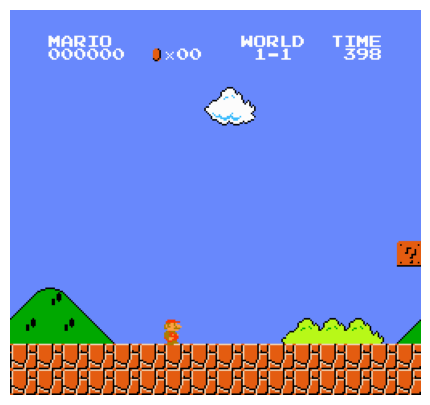

In [29]:
import matplotlib.pyplot as plt
from IPython import display
from stable_baselines3 import PPO

# 1. Load the newly trained 100k checkpoint
model = PPO.load("mario_ppo_100k")

# 2. Reset environment and get raw emulator handle
state = env.reset()
raw_emulator = env.envs[0].unwrapped

# 3. Setup canvas
fig, ax = plt.subplots(figsize=(6, 5))
img = ax.imshow(raw_emulator.screen)
plt.axis('off')

try:
    for step in range(2500):
        # AI predicts next move
        action, _ = model.predict(state, deterministic=True)
        state, reward, done, info = env.step(action)
        
        # Render updated game frame
        img.set_data(raw_emulator.screen)
        display.display(plt.gcf())
        display.clear_output(wait=True)
        
        if done[0]:
            state = env.reset()

finally:
    plt.close(fig)

Reading events from: ./logs/PPO_3/events.out.tfevents.1794057822.Ananyas-MacBook-Air.local.14230.2
Available metrics: ['time/fps', 'train/approx_kl', 'train/clip_fraction', 'train/clip_range', 'train/entropy_loss', 'train/explained_variance', 'train/learning_rate', 'train/loss', 'train/policy_gradient_loss', 'train/value_loss']


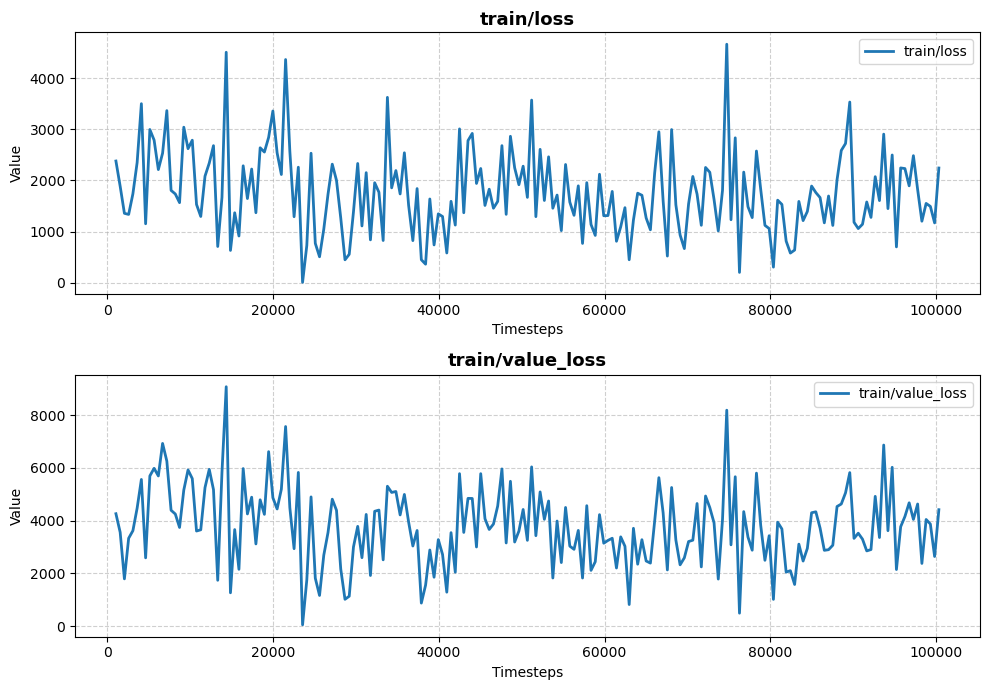

Curves plotted and saved to 'mario_training_curves.png'!


In [30]:
import os
import glob
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# 1. Locate the latest TensorBoard event file inside ./logs/
event_files = glob.glob('./logs/**/events.out.tfevents.*', recursive=True)

if not event_files:
    print("No TensorBoard event files found in ./logs/")
else:
    # Use the most recently modified log file
    latest_event_file = max(event_files, key=os.path.getmtime)
    print(f"Reading events from: {latest_event_file}")

    # 2. Load the scalars from the event file
    ea = EventAccumulator(latest_event_file, size_guidance={'scalars': 0})
    ea.Reload()

    # Available scalar tags
    scalar_tags = ea.Tags().get('scalars', [])
    print("Available metrics:", scalar_tags)

    # 3. Choose the key training metrics to plot
    target_metrics = [
        'rollout/ep_rew_mean', 
        'rollout/ep_len_mean', 
        'train/loss', 
        'train/value_loss'
    ]
    plottable = [m for m in target_metrics if m in scalar_tags]

    if not plottable:
        # Fallback to whatever scalars exist if exact names differ
        plottable = scalar_tags[:4]

    # 4. Generate the plots
    fig, axes = plt.subplots(len(plottable), 1, figsize=(10, 3.5 * len(plottable)), sharex=False)
    if len(plottable) == 1:
        axes = [axes]

    for ax, tag in zip(axes, plottable):
        events = ea.Scalars(tag)
        steps = [e.step for e in events]
        values = [e.value for e in events]

        ax.plot(steps, values, color='#1f77b4', linewidth=2, label=tag)
        ax.set_title(tag, fontsize=13, fontweight='bold')
        ax.set_xlabel('Timesteps', fontsize=10)
        ax.set_ylabel('Value', fontsize=10)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(loc='best')

    plt.tight_layout()
    plt.savefig('mario_training_curves.png', dpi=300)
    plt.show()
    print("Curves plotted and saved to 'mario_training_curves.png'!")

In [31]:
import cv2
import time
from stable_baselines3 import PPO

# 1. Load the trained model
model = PPO.load("mario_ppo_100k")

# 2. Reset the environment and get emulator handle
state = env.reset()
raw_emulator = env.envs[0].unwrapped

window_name = "Super Mario Bros - PPO Agent"
cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
# Scale up the NES resolution (256x240) to 768x720 so it looks crisp on your screen
cv2.resizeWindow(window_name, 768, 720)

print("Game running in separate window! Press 'q' on the Mario window to exit.")

try:
    while True:
        # Predict action
        action, _ = model.predict(state, deterministic=True)
        state, reward, done, info = env.step(action)
        
        # Grab raw RGB frame and convert to BGR for OpenCV
        rgb_frame = raw_emulator.screen
        bgr_frame = cv2.cvtColor(rgb_frame, cv2.COLOR_RGB2BGR)
        
        # Display in floating window
        cv2.imshow(window_name, bgr_frame)
        
        # Run at ~60 FPS (approx 16ms delay)
        # Press 'q' to stop
        if cv2.waitKey(16) & 0xFF == ord('q'):
            break
            
        if done[0]:
            state = env.reset()

finally:
    cv2.destroyAllWindows()
    cv2.waitKey(1)
    print("Window closed.")

Game running in separate window! Press 'q' on the Mario window to exit.
Window closed.
